# Introduction

You are welcome to fork this notebook, improve it, and try to get a better score on the competition leaderboard.

Import the packages that will be used:

In [1]:
import os
import kagglehub

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

Download the competition dataset:

In [2]:
path = kagglehub.competition_download('titanic-survival-2026')

path

'C:\\Users\\ricky\\.cache\\kagglehub\\competitions\\titanic-survival-2026'

# Training data

Read the training data from a CSV file, using the *id* column as index:

In [3]:
df = pd.read_csv(os.path.join(path, 'train.csv'), index_col='id')

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,cabin,embarked,survived
id,,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,NaN,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,NaN,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,B80,C,1
4,3,"Shellard, Mr. Frederick William",male,NaN,0,0,C.A. 6212,15.1000,NaN,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,B96 B98,S,1
...,...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,NaN,S,0
1044,3,"Ryan, Mr. Patrick",male,NaN,0,0,371110,24.1500,NaN,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,NaN,S,1


Observe that the columns contain different types of data:

In [4]:
df.dtypes.to_frame(name='dtype')

,dtype
pclass,int64
name,str
gender,str
age,float64
sibsp,int64
parch,int64
ticket,str
fare,float64
cabin,str
embarked,str


Also, observe that some columns have missing values (NaN):

In [5]:
df.isna().sum(axis=0).to_frame(name='missing')

,missing
pclass,0
name,0
gender,0
age,213
sibsp,0
parch,0
ticket,0
fare,1
cabin,814
embarked,2


From these results, we conclude that:
* for *cabin*, most values are missing;
* for *age*, there are many missing values;
* for *embarked*, there are a few missing values;
* for *fare*, there is only one missing value.

# Missing values

For *cabin*, most values are missing, so we will simply drop this column:

In [6]:
df.drop('cabin', axis=1, inplace=True)

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,embarked,survived
id,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C,1
4,3,"Shellard, Mr. Frederick William",male,NaN,0,0,C.A. 6212,15.1000,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,S,1
...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,S,0
1044,3,"Ryan, Mr. Patrick",male,NaN,0,0,371110,24.1500,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,S,1


For *age*, there are many missing values. We will fix this by using the median:

In [7]:
median_age = df['age'].median()

print(median_age)

28.0


Replace missing values in *age* by the median:

In [8]:
df['age'] = df['age'].fillna(median_age)

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,embarked,survived
id,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C,1
4,3,"Shellard, Mr. Frederick William",male,28.0,0,0,C.A. 6212,15.1000,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,S,1
...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,S,0
1044,3,"Ryan, Mr. Patrick",male,28.0,0,0,371110,24.1500,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,S,1


For *embarked*, there are few missing values. We will fix this by using the mode (i.e. the most frequent value, or one of the most frequent values, if there are ties):

In [9]:
mode_embarked = df['embarked'].mode()[0]

mode_embarked

'S'

Replace missing values in *embarked* by the mode:

In [10]:
df['embarked'] = df['embarked'].fillna(mode_embarked)

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,embarked,survived
id,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C,1
4,3,"Shellard, Mr. Frederick William",male,28.0,0,0,C.A. 6212,15.1000,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,S,1
...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,S,0
1044,3,"Ryan, Mr. Patrick",male,28.0,0,0,371110,24.1500,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,S,1


For *fare*, there is only one missing value. We will fix this by using the mean:

In [11]:
mean_fare = df['fare'].mean()

print(mean_fare)

33.053110325047804


Replace missing values in *fare* by the mean:

In [12]:
df['fare'] = df['fare'].fillna(mean_fare)

df

,pclass,name,gender,age,sibsp,parch,ticket,fare,embarked,survived
id,,,,,,,,,,
1,2,"Hart, Miss. Eva Miriam",female,7.0,0,2,F.C.C. 13529,26.2500,S,1
2,2,"Peruschitz, Rev. Joseph Maria",male,41.0,0,0,237393,13.0000,S,0
3,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C,1
4,3,"Shellard, Mr. Frederick William",male,28.0,0,0,C.A. 6212,15.1000,S,0
5,1,"Carter, Mrs. William Ernest (Lucile Polk)",female,36.0,1,2,113760,120.0000,S,1
...,...,...,...,...,...,...,...,...,...,...
1043,3,"Vande Walle, Mr. Nestor Cyriel",male,28.0,0,0,345770,9.5000,S,0
1044,3,"Ryan, Mr. Patrick",male,28.0,0,0,371110,24.1500,Q,0
1045,3,"Asplund, Master. Edvin Rojj Felix",male,3.0,4,2,347077,31.3875,S,1


# Feature cardinality

Analyze the number of unique values in each column:

In [13]:
df.nunique().sort_values(ascending=False).to_frame(name='nunique')

,nunique
name,1046
ticket,780
fare,269
age,94
parch,8
sibsp,7
pclass,3
embarked,3
gender,2
survived,2


Observe that *name* is a string and has high cardinality (i.e. almost every passenger has a different name):

In [14]:
df['name'].to_frame()

,name
id,
1,"Hart, Miss. Eva Miriam"
2,"Peruschitz, Rev. Joseph Maria"
3,"Lurette, Miss. Elise"
4,"Shellard, Mr. Frederick William"
5,"Carter, Mrs. William Ernest (Lucile Polk)"
...,...
1043,"Vande Walle, Mr. Nestor Cyriel"
1044,"Ryan, Mr. Patrick"
1045,"Asplund, Master. Edvin Rojj Felix"


Since most names appear only once, this is not very useful for prediction, so we will drop this column:

In [15]:
df.drop('name', axis=1, inplace=True)

df

,pclass,gender,age,sibsp,parch,ticket,fare,embarked,survived
id,,,,,,,,,
1,2,female,7.0,0,2,F.C.C. 13529,26.2500,S,1
2,2,male,41.0,0,0,237393,13.0000,S,0
3,1,female,58.0,0,0,PC 17569,146.5208,C,1
4,3,male,28.0,0,0,C.A. 6212,15.1000,S,0
5,1,female,36.0,1,2,113760,120.0000,S,1
...,...,...,...,...,...,...,...,...,...
1043,3,male,28.0,0,0,345770,9.5000,S,0
1044,3,male,28.0,0,0,371110,24.1500,Q,0
1045,3,male,3.0,4,2,347077,31.3875,S,1


The same applies to *ticket* (i.e. *ticket* is a string and has high cardinality):

In [16]:
df['ticket'].to_frame()

,ticket
id,
1,F.C.C. 13529
2,237393
3,PC 17569
4,C.A. 6212
5,113760
...,...
1043,345770
1044,371110
1045,347077


We will drop the *ticket* column as well:

In [17]:
df.drop('ticket', axis=1, inplace=True)

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived
id,,,,,,,,
1,2,female,7.0,0,2,26.2500,S,1
2,2,male,41.0,0,0,13.0000,S,0
3,1,female,58.0,0,0,146.5208,C,1
4,3,male,28.0,0,0,15.1000,S,0
5,1,female,36.0,1,2,120.0000,S,1
...,...,...,...,...,...,...,...,...
1043,3,male,28.0,0,0,9.5000,S,0
1044,3,male,28.0,0,0,24.1500,Q,0
1045,3,male,3.0,4,2,31.3875,S,1


*Fare* and *age* have high cardinality, but these are numeric variables, so we will keep them:

In [18]:
df[['age', 'fare']]

,age,fare
id,,
1,7.0,26.2500
2,41.0,13.0000
3,58.0,146.5208
4,28.0,15.1000
5,36.0,120.0000
...,...,...
1043,28.0,9.5000
1044,28.0,24.1500
1045,3.0,31.3875


# Categorical features

The *gender* column is a categorical feature with only two possible values:

In [19]:
gender_values = sorted(df['gender'].unique())

gender_values

['female', 'male']

To convert the *gender* column to a numeric feature, we will use value indexing:

In [20]:
gender_mapping = {gender: i for i, gender in enumerate(gender_values)}

gender_mapping

{'female': 0, 'male': 1}

Now convert the *gender* column to a numeric feature:

In [21]:
df['gender'] = df['gender'].map(gender_mapping)

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived
id,,,,,,,,
1,2,0,7.0,0,2,26.2500,S,1
2,2,1,41.0,0,0,13.0000,S,0
3,1,0,58.0,0,0,146.5208,C,1
4,3,1,28.0,0,0,15.1000,S,0
5,1,0,36.0,1,2,120.0000,S,1
...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,S,0
1044,3,1,28.0,0,0,24.1500,Q,0
1045,3,1,3.0,4,2,31.3875,S,1


In [22]:
df['age_x_gender'] = df['age'] * df['gender']

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived,age_x_gender
id,,,,,,,,,
1,2,0,7.0,0,2,26.2500,S,1,0.0
2,2,1,41.0,0,0,13.0000,S,0,41.0
3,1,0,58.0,0,0,146.5208,C,1,0.0
4,3,1,28.0,0,0,15.1000,S,0,28.0
5,1,0,36.0,1,2,120.0000,S,1,0.0
...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,S,0,28.0
1044,3,1,28.0,0,0,24.1500,Q,0,28.0
1045,3,1,3.0,4,2,31.3875,S,1,3.0


The *embarked* column is a categorical feature with three possible values:

In [23]:
embarked_values = sorted(df['embarked'].unique())

embarked_values

['C', 'Q', 'S']

To convert the *embarked* column, we will use *one-hot encoding*:

In [24]:
encoder = OneHotEncoder(sparse_output=False, dtype=int)

encoder

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'int'>
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent_categori

Fit the one-hot encoder to the *embarked* column:

In [25]:
encoder.fit(df[['embarked']])

,"sparse_output sparse_output: bool, default=TrueWhen ``True``, it returns a SciPy sparse matrix/arrayin ""Compressed Sparse Row"" (CSR) format... versionadded:: 1.2 `sparse` was renamed to `sparse_output`",False
,"dtype dtype: number type, default=np.float64Desired dtype of output.",<class 'int'>
,"categories categories: 'auto' or a list of array-like, default='auto'Categories (unique values) per feature:- 'auto' : Determine categories automatically from the training data.- list : ``categories[i]`` holds the categories expected in the ith column. The passed categories should not mix strings and numeric values within a single feature, and should be sorted in case of numeric values.The used categories can be found in the ``categories_`` attribute... versionadded:: 0.20",'auto'
,"drop drop: {'first', 'if_binary'} or an array-like of shape (n_features,), default=NoneSpecifies a methodology to use to drop one of the categories perfeature. This is useful in situations where perfectly collinearfeatures cause problems, such as when feeding the resulting datainto an unregularized linear regression model.However, dropping one category breaks the symmetry of the originalrepresentation and can therefore induce a bias in downstream models,for instance for penalized linear classification or regression models.- None : retain all features (the default).- 'first' : drop the first category in each feature. If only one category is present, the feature will be dropped entirely.- 'if_binary' : drop the first category in each feature with two categories. Features with 1 or more than 2 categories are left intact.- array : ``drop[i]`` is the category in feature ``X[:, i]`` that should be dropped.When `max_categories` or `min_frequency` is configured to groupinfrequent categories, the dropping behavior is handled after thegrouping... versionadded:: 0.21 The parameter `drop` was added in 0.21... versionchanged:: 0.23 The option `drop='if_binary'` was added in 0.23... versionchanged:: 1.1 Support for dropping infrequent categories.",None
,"handle_unknown handle_unknown: {'error', 'ignore', 'infrequent_if_exist', 'warn'}, default='error'Specifies the way unknown categories are handled during :meth:`transform`.- 'error' : Raise an error if an unknown category is present during transform.- 'ignore' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will be all zeros. In the inverse transform, an unknown category will be denoted as None.- 'infrequent_if_exist' : When an unknown category is encountered during transform, the resulting one-hot encoded columns for this feature will map to the infrequent category if it exists. The infrequent category will be mapped to the last position in the encoding. During inverse transform, an unknown category will be mapped to the category denoted `'infrequent'` if it exists. If the `'infrequent'` category does not exist, then :meth:`transform` and :meth:`inverse_transform` will handle an unknown category as with `handle_unknown='ignore'`. Infrequent categories exist based on `min_frequency` and `max_categories`. Read more in the :ref:`User Guide <encoder_infrequent_categories>`.- 'warn' : When an unknown category is encountered during transform a warning is issued, and the encoding then proceeds as described for `handle_unknown=""infrequent_if_exist""`... versionchanged:: 1.1 `'infrequent_if_exist'` was added to automatically handle unknown categories and infrequent categories... versionadded:: 1.6 The option `""warn""` was added in 1.6.",'error'
,"min_frequency min_frequency: int or float, default=NoneSpecifies the minimum frequency below which a category will beconsidered infrequent.- If `int`, categories with a smaller cardinality will be considered infrequent.- If `float`, categories with a smaller cardinality than `min_frequency * n_samples` will be considered infrequent... versionadded:: 1.1 Read more in the :ref:`User Guide <encoder_infrequent_categori

The new columns for this *one-hot encoding* will be:

In [26]:
embarked_columns = encoder.get_feature_names_out().tolist()

embarked_columns

['embarked_C', 'embarked_Q', 'embarked_S']

Now convert the *embarked* column to these new columns:

In [27]:
df[embarked_columns] = encoder.transform(df[['embarked']])

df

,pclass,gender,age,sibsp,parch,fare,embarked,survived,age_x_gender,embarked_C,embarked_Q,embarked_S
id,,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,S,1,0.0,0,0,1
2,2,1,41.0,0,0,13.0000,S,0,41.0,0,0,1
3,1,0,58.0,0,0,146.5208,C,1,0.0,1,0,0
4,3,1,28.0,0,0,15.1000,S,0,28.0,0,0,1
5,1,0,36.0,1,2,120.0000,S,1,0.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,S,0,28.0,0,0,1
1044,3,1,28.0,0,0,24.1500,Q,0,28.0,0,1,0
1045,3,1,3.0,4,2,31.3875,S,1,3.0,0,0,1


Drop the original *embarked* column:

In [28]:
df.drop('embarked', axis=1, inplace=True)

df

,pclass,gender,age,sibsp,parch,fare,survived,age_x_gender,embarked_C,embarked_Q,embarked_S
id,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,1,0.0,0,0,1
2,2,1,41.0,0,0,13.0000,0,41.0,0,0,1
3,1,0,58.0,0,0,146.5208,1,0.0,1,0,0
4,3,1,28.0,0,0,15.1000,0,28.0,0,0,1
5,1,0,36.0,1,2,120.0000,1,0.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,0,28.0,0,0,1
1044,3,1,28.0,0,0,24.1500,0,28.0,0,1,0
1045,3,1,3.0,4,2,31.3875,1,3.0,0,0,1


# Feature engineering

In this dataset:
* *sibsp* is the number of siblings and spouses traveling with the passenger;
* *parch* is the number of parents and children traveling with the passenger.

To predict survival, it might be useful to know if a passenger was traveling alone or not.

Therefore, we create the following feature:

In [29]:
df['alone'] = ((df['sibsp'] + df['parch']) == 0).astype(int)

df

,pclass,gender,age,sibsp,parch,fare,survived,age_x_gender,embarked_C,embarked_Q,embarked_S,alone
id,,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,1,0.0,0,0,1,0
2,2,1,41.0,0,0,13.0000,0,41.0,0,0,1,1
3,1,0,58.0,0,0,146.5208,1,0.0,1,0,0,1
4,3,1,28.0,0,0,15.1000,0,28.0,0,0,1,1
5,1,0,36.0,1,2,120.0000,1,0.0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,0,28.0,0,0,1,1
1044,3,1,28.0,0,0,24.1500,0,28.0,0,1,0,1
1045,3,1,3.0,4,2,31.3875,1,3.0,0,0,1,0


Also, it might be useful to know size of the family that the passenger is travelling with (including the passenger):

In [30]:
df['family'] = df['sibsp'] + df['parch'] + 1
df['fare_per_family'] = df['fare'] / df['family']

df

,pclass,gender,age,sibsp,parch,fare,survived,age_x_gender,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family
id,,,,,,,,,,,,,,
1,2,0,7.0,0,2,26.2500,1,0.0,0,0,1,0,3,8.750000
2,2,1,41.0,0,0,13.0000,0,41.0,0,0,1,1,1,13.000000
3,1,0,58.0,0,0,146.5208,1,0.0,1,0,0,1,1,146.520800
4,3,1,28.0,0,0,15.1000,0,28.0,0,0,1,1,1,15.100000
5,1,0,36.0,1,2,120.0000,1,0.0,0,0,1,0,4,30.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1043,3,1,28.0,0,0,9.5000,0,28.0,0,0,1,1,1,9.500000
1044,3,1,28.0,0,0,24.1500,0,28.0,0,1,0,1,1,24.150000
1045,3,1,3.0,4,2,31.3875,1,3.0,0,0,1,0,7,4.483929


# Data splitting

Select the target column and the feature columns:

In [31]:
target_column = 'survived'

feature_columns = [col for col in df.columns if col != target_column]

feature_columns

['pclass',
 'gender',
 'age',
 'sibsp',
 'parch',
 'fare',
 'age_x_gender',
 'embarked_C',
 'embarked_Q',
 'embarked_S',
 'alone',
 'family',
 'fare_per_family']

Split the training data into a training set and a validation set:

In [32]:
df_train, df_valid = train_test_split(df,
                                      test_size=0.2,
                                      random_state=0,
                                      stratify=df[target_column])

print(df_train.shape, df_valid.shape)

(837, 14) (210, 14)


The use of *stratify* above ensures that the training set and the validation set have approximately the same class distribution:

In [33]:
pd.concat([df_train[target_column].value_counts(normalize=True),
           df_valid[target_column].value_counts(normalize=True)],
          axis=1, keys=['train', 'val']).style.format('{:.1%}')

,train,val
survived,,
0,61.8%,61.9%
1,38.2%,38.1%


# Model fitting

Create a decision tree classifier:

In [34]:
model = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=0)

model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Fit the classifier to the training set:

In [35]:
model.fit(df_train[feature_columns], df_train[target_column])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Plot the decision tree:

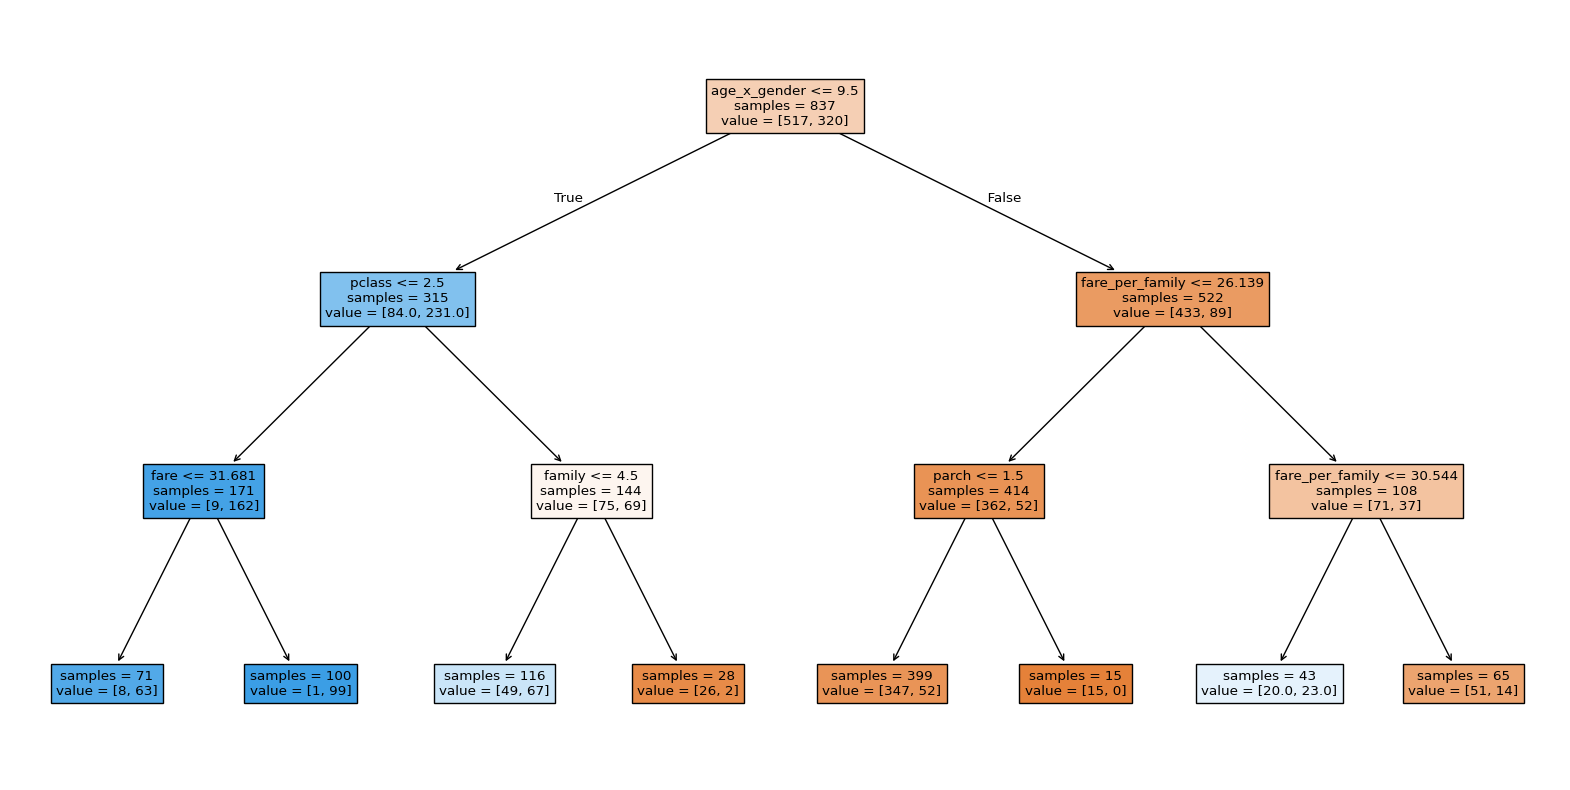

In [36]:
plt.figure(figsize=(20, 10))

plot_tree(model, feature_names=feature_columns, filled=True, impurity=False);

Take a moment to interpret the decision tree above.

# Feature importance

It is possible to get the features importances from this model:

In [37]:
feature_importances = pd.Series(model.feature_importances_, index=feature_columns)

feature_importances.to_frame(name='importance')

,importance
pclass,0.215007
gender,0.000000
age,0.000000
sibsp,0.000000
parch,0.009251
fare,0.021000
age_x_gender,0.611347
embarked_C,0.000000
embarked_Q,0.000000
embarked_S,0.000000


We can also present the feature importances in a bar chart:

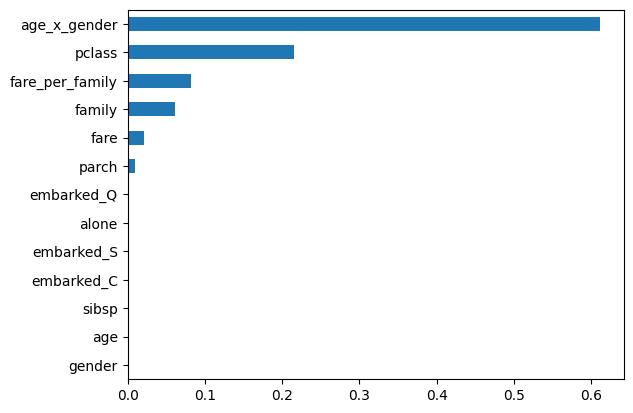

In [38]:
feature_importances.sort_values().plot.barh();

# Model evaluation

To evaluate the model, make predictions on the validation set:

In [39]:
predict_column = 'prediction'

df_valid[predict_column] = model.predict(df_valid[feature_columns])

df_valid

,pclass,gender,age,sibsp,parch,fare,survived,age_x_gender,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,prediction
id,,,,,,,,,,,,,,,
531,3,0,31.0,1,1,20.5250,1,0.0,0,0,1,0,3,6.841667,1
937,3,0,5.0,0,0,12.4750,1,0.0,0,0,1,1,1,12.475000,1
836,1,1,50.0,1,0,106.4250,0,50.0,1,0,0,0,2,53.212500,0
884,3,0,36.0,0,2,15.9000,1,0.0,0,0,1,0,3,5.300000,1
690,3,1,22.0,0,0,7.2500,0,22.0,0,0,1,1,1,7.250000,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
645,2,1,40.0,0,0,13.0000,0,40.0,0,0,1,1,1,13.000000,0
314,3,1,38.0,0,0,7.8958,0,38.0,0,0,1,1,1,7.895800,0
944,3,1,28.0,0,0,7.7500,1,28.0,0,1,0,1,1,7.750000,0


From the target column and the predictions, we can compute several metrics:

In [40]:
accuracy  =  accuracy_score(df_valid[target_column], df_valid[predict_column])
precision = precision_score(df_valid[target_column], df_valid[predict_column])
recall    =    recall_score(df_valid[target_column], df_valid[predict_column])
f1        =        f1_score(df_valid[target_column], df_valid[predict_column])

print(f'accuracy : { accuracy:.3f}')
print(f'precision: {precision:.3f}')
print(f'recall   : {   recall:.3f}')
print(f'f1 score : {       f1:.3f}')

accuracy : 0.819
precision: 0.744
recall   : 0.800
f1 score : 0.771


Also, we can plot the confusion matrix for true vs. predicted labels:

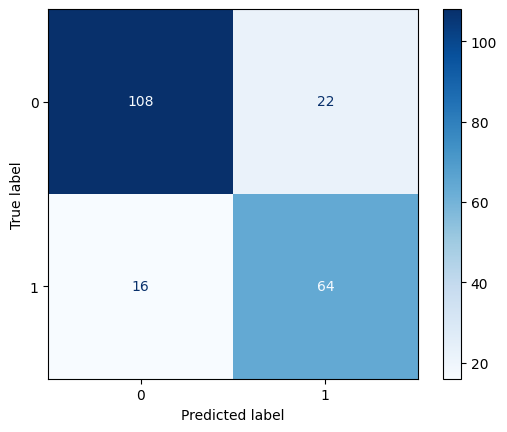

In [41]:
ConfusionMatrixDisplay.from_predictions(df_valid[target_column],
                                        df_valid[predict_column],
                                        cmap='Blues');

The confusion matrix shows the number of *true negatives*, *false positives*, *false_negatives*, and *true positives*:

In [42]:
cm = confusion_matrix(df_valid[target_column], df_valid[predict_column])

print(cm)

[[TN, FP],
 [FN, TP]] = cm

[[108  22]
 [ 16  64]]


From these, we can compute the same metrics ourselves:

In [43]:
accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)

print(f'accuracy : { accuracy:.3f}')
print(f'precision: {precision:.3f}')
print(f'recall   : {   recall:.3f}')
print(f'f1 score : {       f1:.3f}')

accuracy : 0.819
precision: 0.744
recall   : 0.800
f1 score : 0.771


Check that these results agree with the previous ones.

# Test data

Read the test data from a CSV file, using the *id* column as index:

In [44]:
df_test = pd.read_csv(os.path.join(path, 'test.csv'), index_col='id')

df_test

,pclass,name,gender,age,sibsp,parch,ticket,fare,cabin,embarked
id,,,,,,,,,,
1048,3,"Turkula, Mrs. (Hedwig)",female,63.0,0,0,4134,9.5875,NaN,S
1049,2,"Bryhl, Miss. Dagmar Jenny Ingeborg",female,20.0,1,0,236853,26.0000,NaN,S
1050,2,"Knight, Mr. Robert J",male,NaN,0,0,239855,0.0000,NaN,S
1051,2,"Sjostedt, Mr. Ernst Adolf",male,59.0,0,0,237442,13.5000,NaN,S
1052,3,"Aks, Mrs. Sam (Leah Rosen)",female,18.0,0,1,392091,9.3500,NaN,S
...,...,...,...,...,...,...,...,...,...,...
1305,3,"Shorney, Mr. Charles Joseph",male,NaN,0,0,374910,8.0500,NaN,S
1306,1,"Kenyon, Mrs. Frederick R (Marion)",female,NaN,1,0,17464,51.8625,D21,S
1307,2,"Smith, Miss. Marion Elsie",female,40.0,0,0,31418,13.0000,NaN,S


We need to apply the same data processing to the test data, as we did with for the training data, namely:
* drop the *cabin*, *name*, and *ticket* columns;
* fill missing values in *age*, *embarked*, and *fare*;
* convert *gender* and *embarked* to numeric features;
* create the new features *alone* and *family*.

Drop *cabin*, *name*, and *ticket*:

In [45]:
df_test.drop(['cabin', 'name', 'ticket'], axis=1, inplace=True)

df_test

,pclass,gender,age,sibsp,parch,fare,embarked
id,,,,,,,
1048,3,female,63.0,0,0,9.5875,S
1049,2,female,20.0,1,0,26.0000,S
1050,2,male,NaN,0,0,0.0000,S
1051,2,male,59.0,0,0,13.5000,S
1052,3,female,18.0,0,1,9.3500,S
...,...,...,...,...,...,...,...
1305,3,male,NaN,0,0,8.0500,S
1306,1,female,NaN,1,0,51.8625,S
1307,2,female,40.0,0,0,13.0000,S


Fill missing values in *age*, *embarked*, and *fare*:

In [46]:
df_test['age'] = df_test['age'].fillna(median_age)

df_test['embarked'] = df_test['embarked'].fillna(mode_embarked)

df_test['fare'] = df_test['fare'].fillna(mean_fare)

df_test

,pclass,gender,age,sibsp,parch,fare,embarked
id,,,,,,,
1048,3,female,63.0,0,0,9.5875,S
1049,2,female,20.0,1,0,26.0000,S
1050,2,male,28.0,0,0,0.0000,S
1051,2,male,59.0,0,0,13.5000,S
1052,3,female,18.0,0,1,9.3500,S
...,...,...,...,...,...,...,...
1305,3,male,28.0,0,0,8.0500,S
1306,1,female,28.0,1,0,51.8625,S
1307,2,female,40.0,0,0,13.0000,S


Convert *gender* and *embarked* to numeric features:

In [47]:
df_test['gender'] = df_test['gender'].map(gender_mapping)

df_test['age_x_gender'] = df_test['age'] * df_test['gender']

df_test[embarked_columns] = encoder.transform(df_test[['embarked']])

df_test.drop('embarked', axis=1, inplace=True)

df_test

,pclass,gender,age,sibsp,parch,fare,age_x_gender,embarked_C,embarked_Q,embarked_S
id,,,,,,,,,,
1048,3,0,63.0,0,0,9.5875,0.0,0,0,1
1049,2,0,20.0,1,0,26.0000,0.0,0,0,1
1050,2,1,28.0,0,0,0.0000,28.0,0,0,1
1051,2,1,59.0,0,0,13.5000,59.0,0,0,1
1052,3,0,18.0,0,1,9.3500,0.0,0,0,1
...,...,...,...,...,...,...,...,...,...,...
1305,3,1,28.0,0,0,8.0500,28.0,0,0,1
1306,1,0,28.0,1,0,51.8625,0.0,0,0,1
1307,2,0,40.0,0,0,13.0000,0.0,0,0,1


Create the features *alone* and *family*.

In [48]:
df_test['alone'] = ((df_test['sibsp'] + df_test['parch']) == 0).astype(int)

df_test['family'] = df_test['sibsp'] + df_test['parch'] + 1
df_test['fare_per_family'] = df_test['fare'] / df_test['family']

df_test

,pclass,gender,age,sibsp,parch,fare,age_x_gender,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family
id,,,,,,,,,,,,,
1048,3,0,63.0,0,0,9.5875,0.0,0,0,1,1,1,9.58750
1049,2,0,20.0,1,0,26.0000,0.0,0,0,1,0,2,13.00000
1050,2,1,28.0,0,0,0.0000,28.0,0,0,1,1,1,0.00000
1051,2,1,59.0,0,0,13.5000,59.0,0,0,1,1,1,13.50000
1052,3,0,18.0,0,1,9.3500,0.0,0,0,1,0,2,4.67500
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,1,28.0,0,0,8.0500,28.0,0,0,1,1,1,8.05000
1306,1,0,28.0,1,0,51.8625,0.0,0,0,1,0,2,25.93125
1307,2,0,40.0,0,0,13.0000,0.0,0,0,1,1,1,13.00000


Make predictions on the test set:

In [49]:
df_test[target_column] = model.predict(df_test[feature_columns])

df_test

,pclass,gender,age,sibsp,parch,fare,age_x_gender,embarked_C,embarked_Q,embarked_S,alone,family,fare_per_family,survived
id,,,,,,,,,,,,,,
1048,3,0,63.0,0,0,9.5875,0.0,0,0,1,1,1,9.58750,1
1049,2,0,20.0,1,0,26.0000,0.0,0,0,1,0,2,13.00000,1
1050,2,1,28.0,0,0,0.0000,28.0,0,0,1,1,1,0.00000,0
1051,2,1,59.0,0,0,13.5000,59.0,0,0,1,1,1,13.50000,0
1052,3,0,18.0,0,1,9.3500,0.0,0,0,1,0,2,4.67500,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,3,1,28.0,0,0,8.0500,28.0,0,0,1,1,1,8.05000,0
1306,1,0,28.0,1,0,51.8625,0.0,0,0,1,0,2,25.93125,1
1307,2,0,40.0,0,0,13.0000,0.0,0,0,1,1,1,13.00000,1


Prepare a submission:

In [50]:
df_submission = df_test[target_column].to_frame()

df_submission

,survived
id,
1048,1
1049,1
1050,0
1051,0
1052,1
...,...
1305,0
1306,1
1307,1


Save the submission file:

In [51]:
df_submission.to_csv('submission.csv')

Submit this file to the competition, and check your score on the leaderboard!🍀

**Leaderboard Score:** `0.736` (**#3** class overall)